In [ ]:
import cv2
import matplotlib.pyplot as plt
from model import FinetunedSAM
from pipeline import SlidingWindowPipeline
import torch
import numpy as np
from stardist.matching import matching_dataset
from tqdm import tqdm

/home/nathan/miniconda3/envs/SAMed/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Load the model
model = FinetunedSAM('facebook/sam-vit-base', finetune_vision=False, finetune_prompt=True, finetune_decoder=True)
trained_samcell_path = '/home/nathan/Desktop/SAMCell-t4/checkpoints/samcell-cyto/pytorch_model.bin'
model.load_weights(trained_samcell_path)

pipeline = SlidingWindowPipeline(model, 'cuda', crop_size=256)
test_image = np.load('../datasets/LIVECell-test/imgs.npy')[0][:,:,0]
# test_image = cv2.imread('/home/nathan/Desktop/PBL-datasets/processed/imgs/PBL_N2A/10.png', cv2.IMREAD_GRAYSCALE)
#rescale to 1000 (largest dimension)
# if test_image.shape[0] > test_image.shape[1]:
#     test_image = cv2.resize(test_image, (int(test_image.shape[1] * 1000 / test_image.shape[0]), 1000))
# else:
#     test_image = cv2.resize(test_image, (1000, int(test_image.shape[0] * 1000 / test_image.shape[1])))

In [ ]:
def convert_label_to_rainbow(label):
    label_rainbow = np.zeros((label.shape[0], label.shape[1], 3), dtype=np.uint8)
    for cell in np.unique(label):
        if cell == 0:
            continue #background
        label_rainbow[label == cell] = np.random.rand(3) * 255

    return label_rainbow

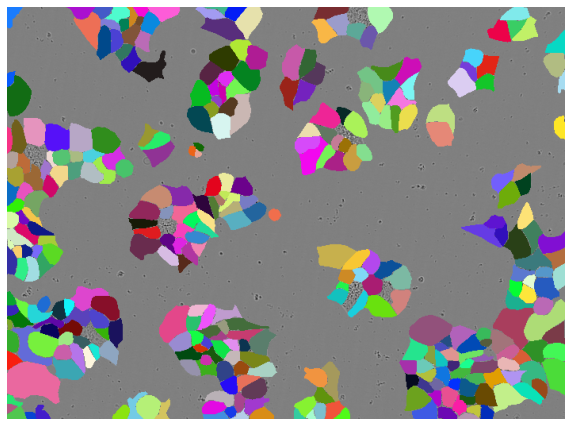

In [ ]:
# Run the pipeline
output = pipeline.run(test_image)
output = np.load('../datasets/LIVECell-test/anns.npy')[0][0]
output_rgb = convert_label_to_rainbow(output)
output_rgb[output == 0] = cv2.cvtColor(test_image, cv2.COLOR_GRAY2RGB)[output == 0]

# Display the output
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
#remove axes
ax.set_xticks([])
ax.set_yticks([])
#set 1 in borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.imshow(output_rgb, cmap='gray')
plt.savefig('raw_img.png')
plt.show()
# ax[1].imshow(output_rgb)
# ax[1].imshow(test_image, cmap='gray', alpha=0.5)
# plt.show()

(68, 512, 512) (68, 512, 512)
running...


  0%|          | 0/68 [00:00<?, ?it/s]

0
(512, 512)


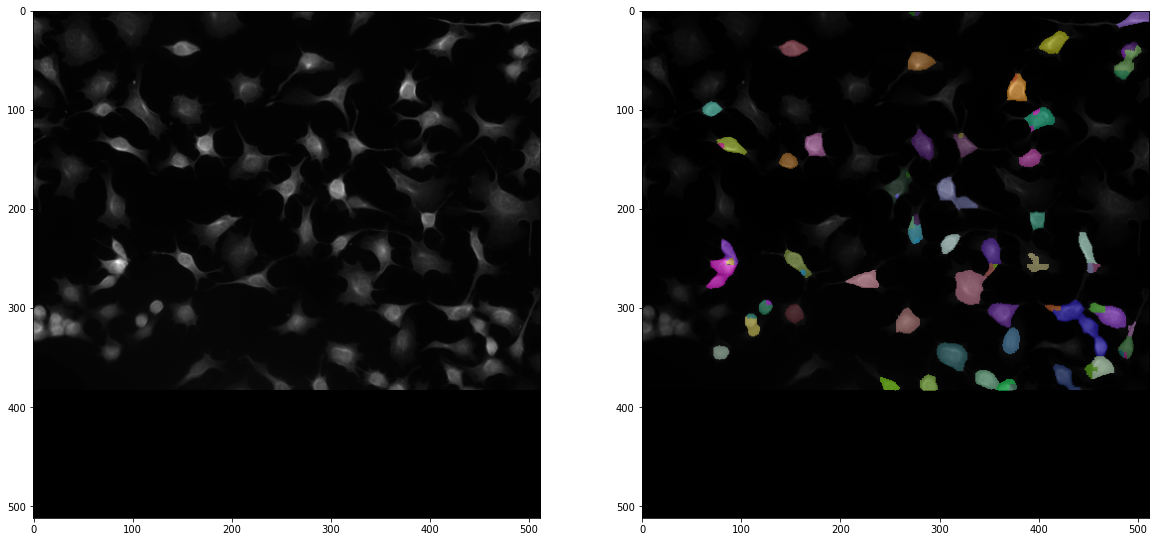

  1%|▏         | 1/68 [00:01<01:42,  1.54s/it]

1
(512, 512)


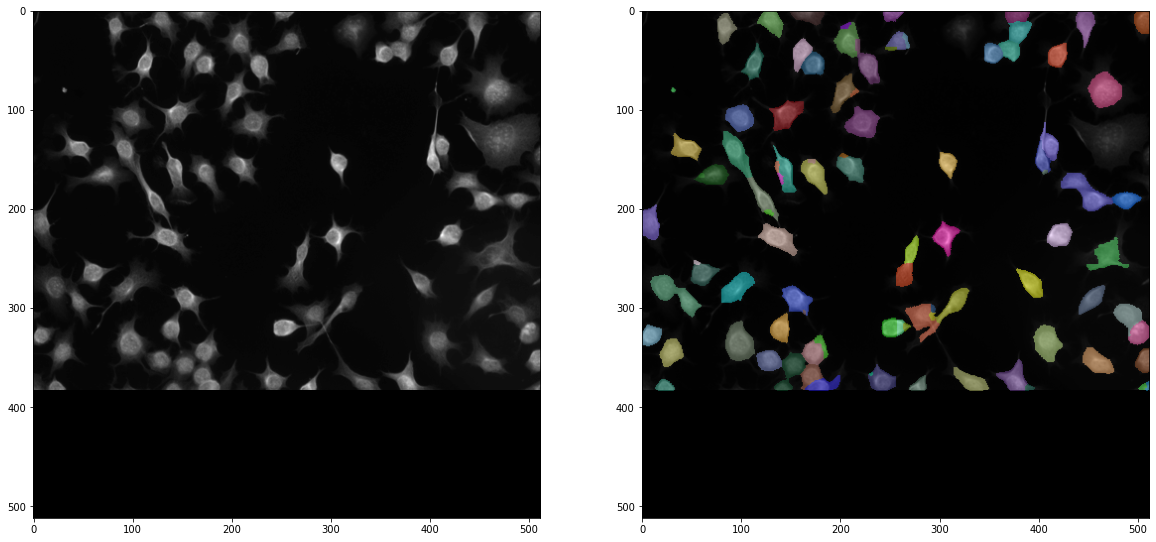

  3%|▎         | 2/68 [00:02<01:22,  1.24s/it]

2
(512, 512)


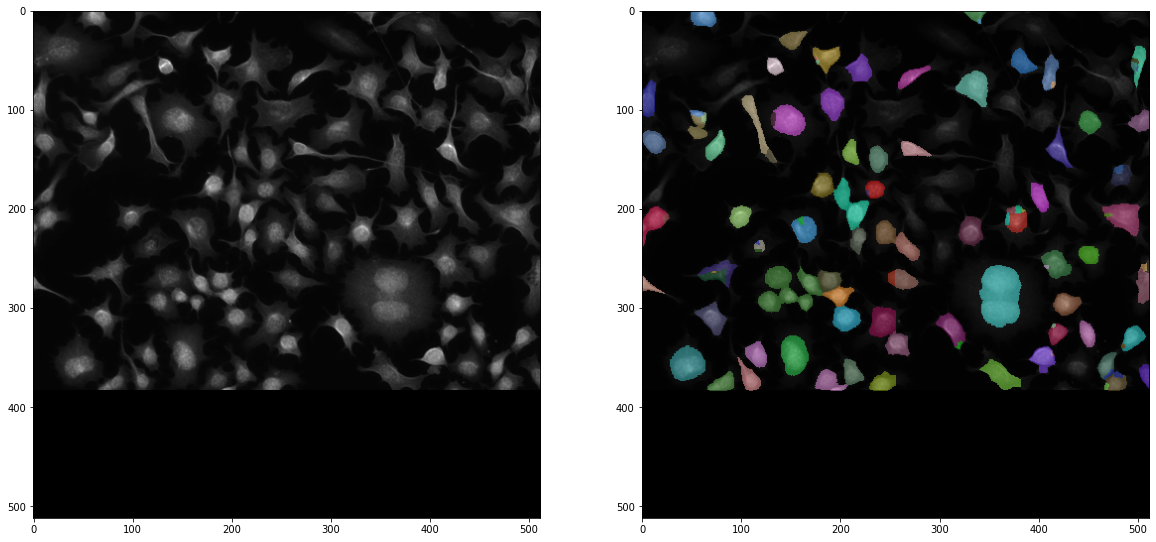

  4%|▍         | 3/68 [00:03<01:16,  1.18s/it]

3
(512, 512)


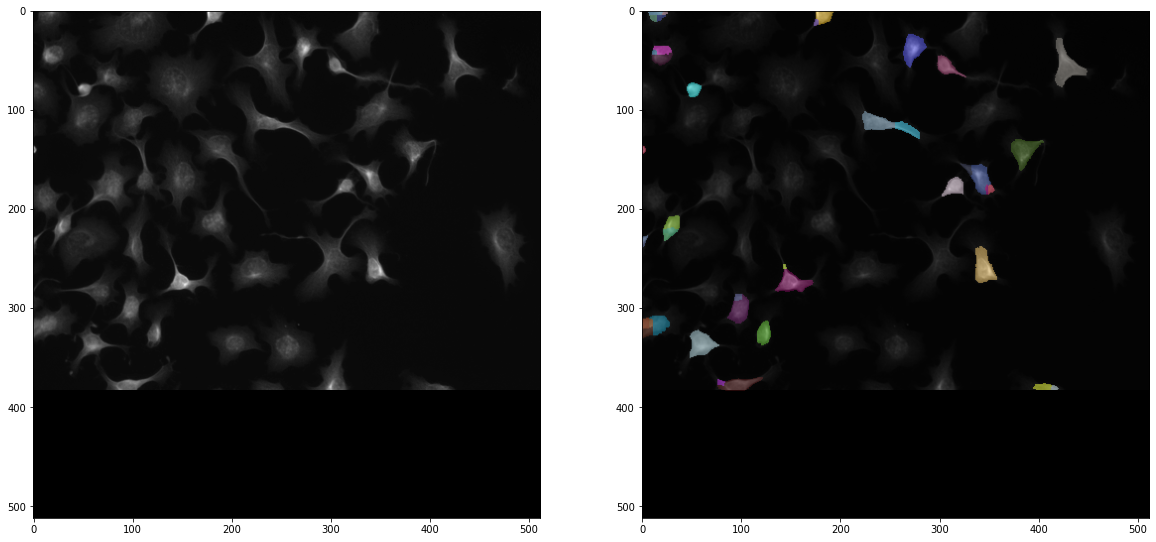

  6%|▌         | 4/68 [00:04<01:12,  1.13s/it]

4
(512, 512)


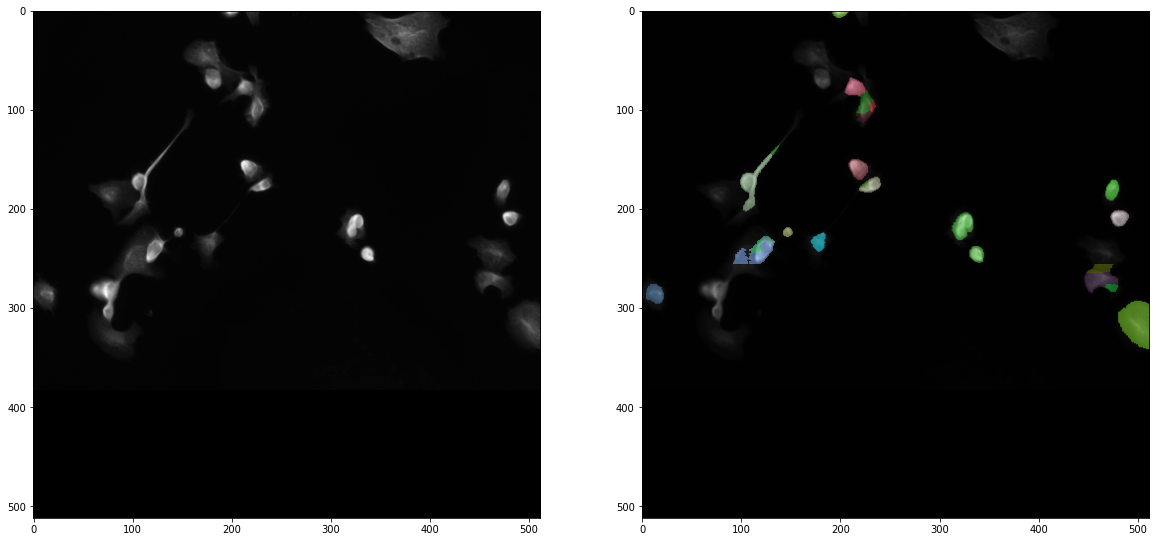

  7%|▋         | 5/68 [00:05<01:09,  1.10s/it]

5
(512, 512)


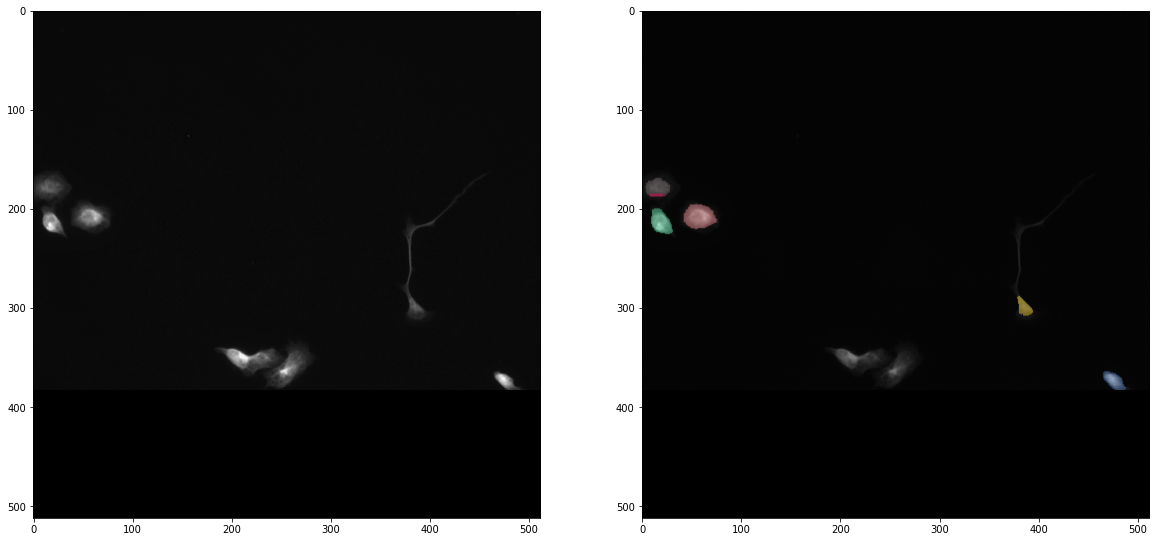

  9%|▉         | 6/68 [00:06<01:06,  1.07s/it]

6
(512, 512)


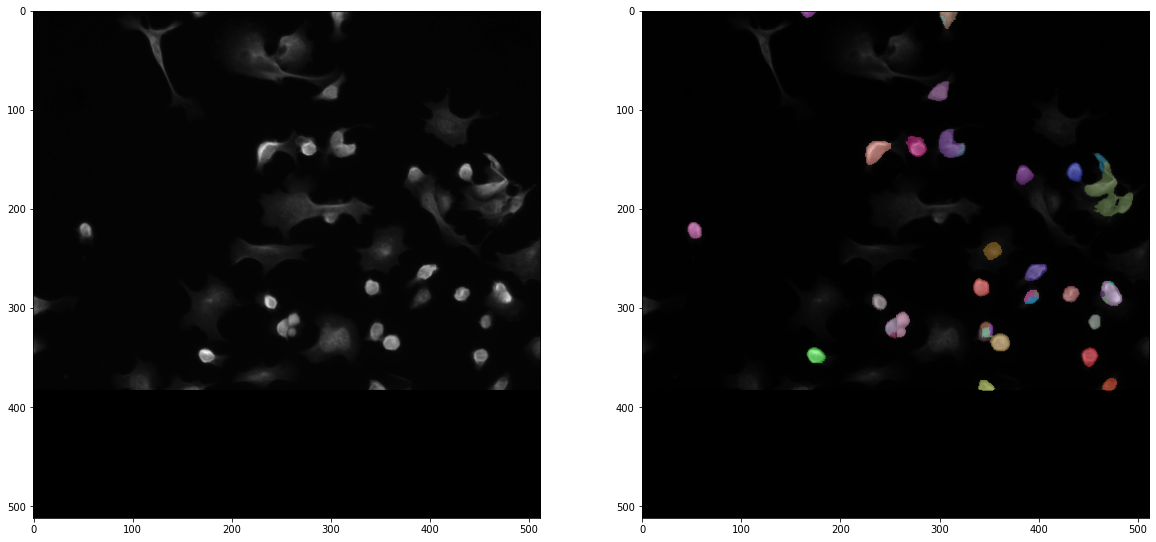

 10%|█         | 7/68 [00:07<01:04,  1.05s/it]

7
(512, 512)


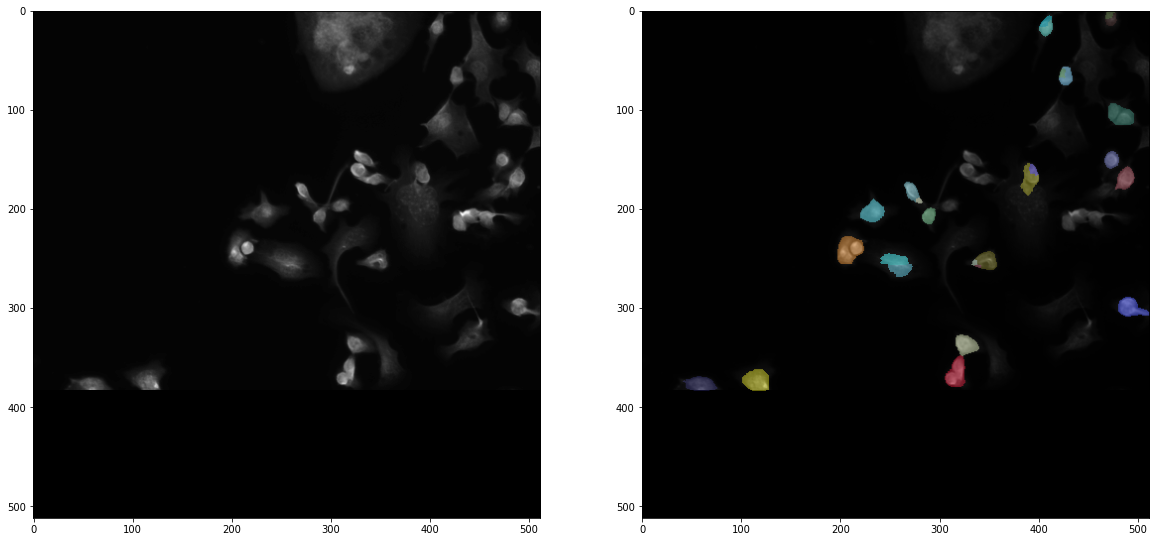

 12%|█▏        | 8/68 [00:08<01:02,  1.04s/it]

8
(512, 512)


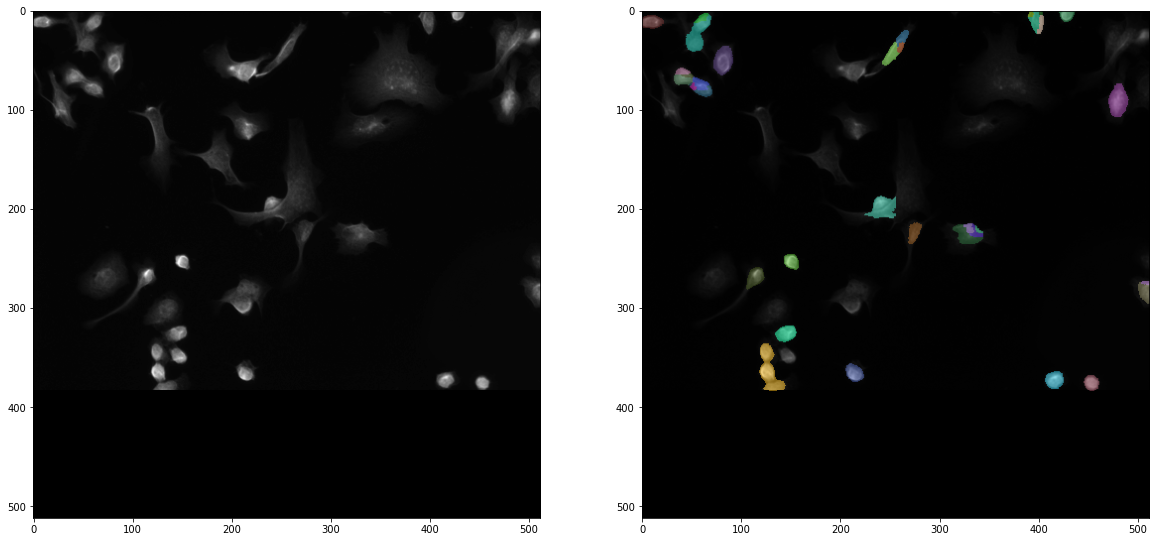

 13%|█▎        | 9/68 [00:09<01:01,  1.04s/it]

9
(512, 512)


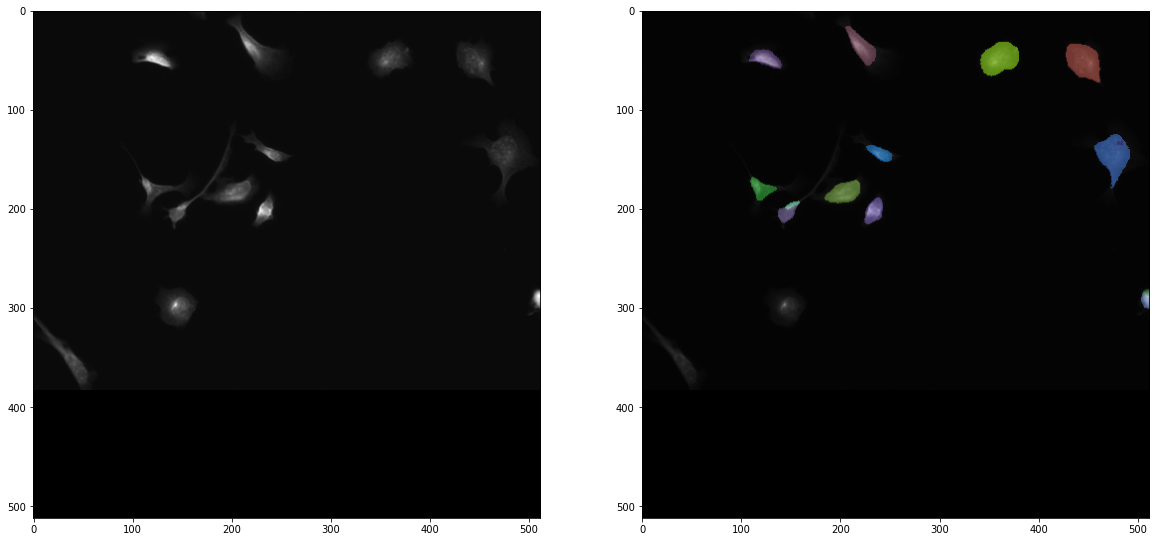

 15%|█▍        | 10/68 [00:10<01:00,  1.04s/it]

10
(512, 512)


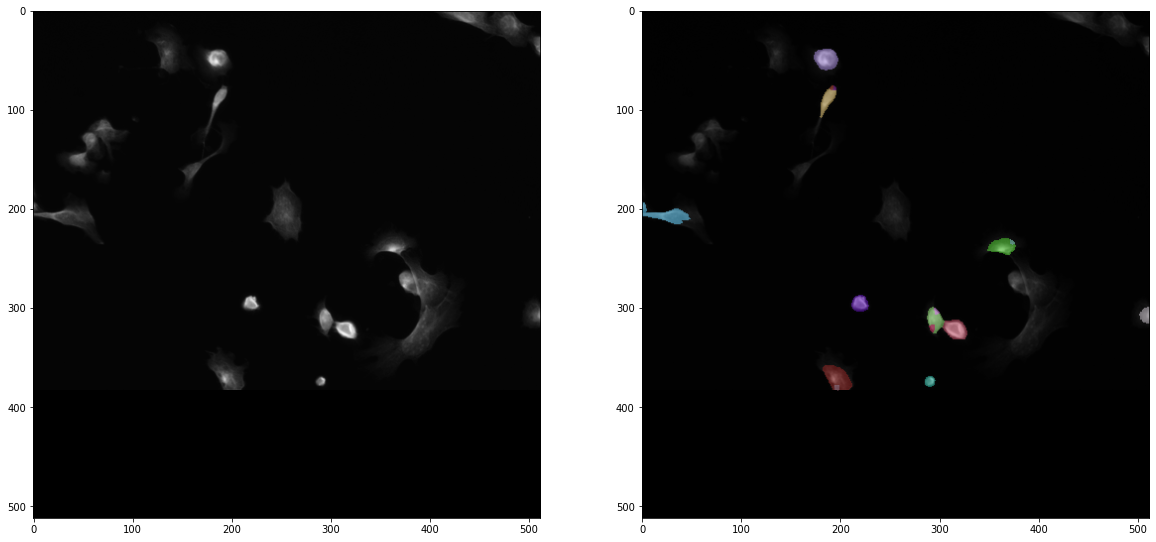

 16%|█▌        | 11/68 [00:11<00:59,  1.04s/it]

11
(512, 512)


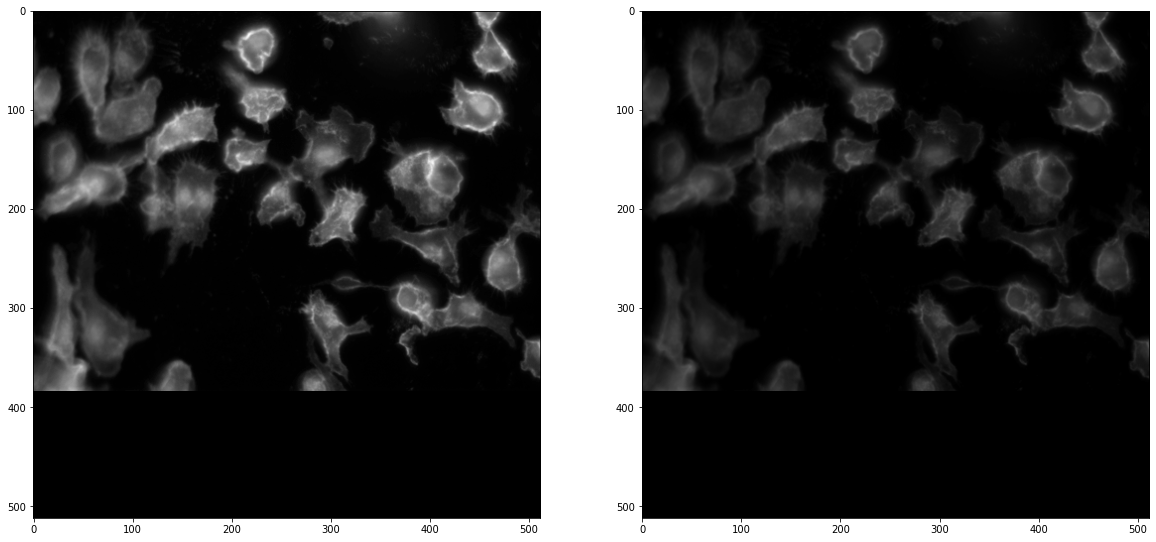

 18%|█▊        | 12/68 [00:12<00:58,  1.04s/it]

12
(512, 512)


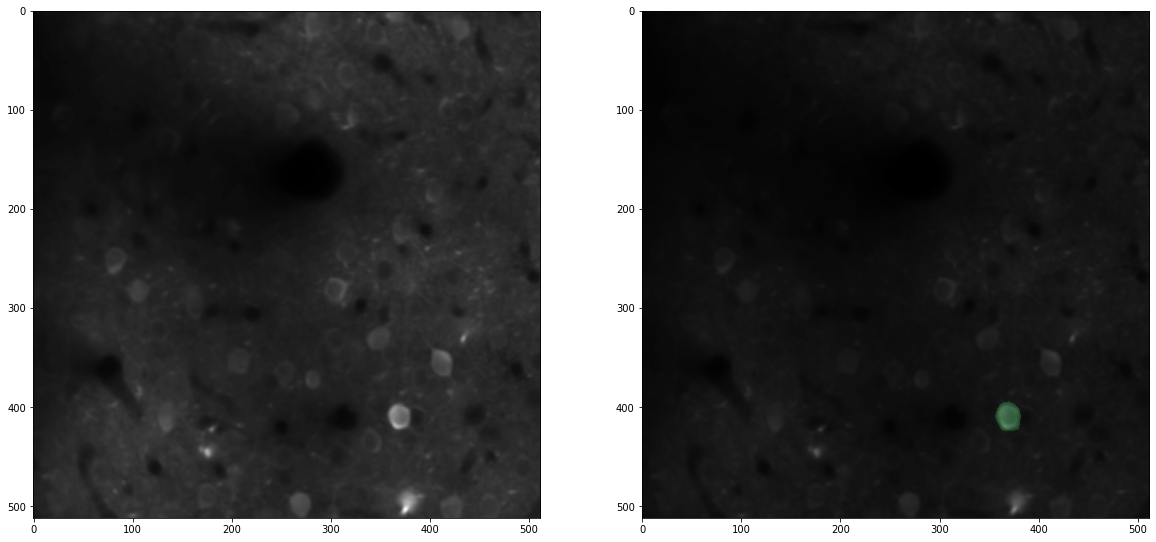

 19%|█▉        | 13/68 [00:14<00:57,  1.04s/it]

13
(512, 512)


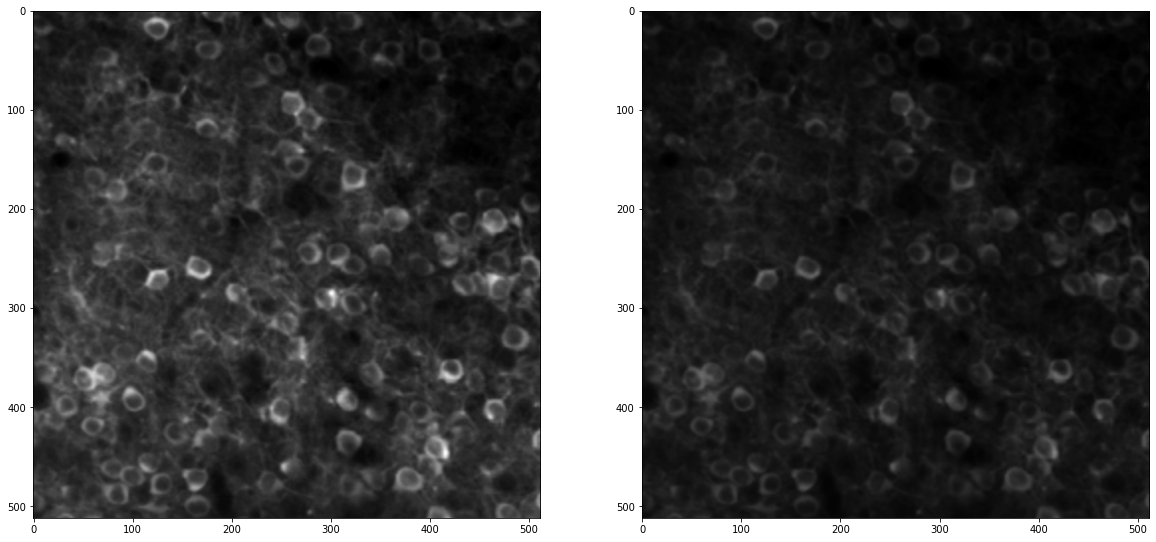

 21%|██        | 14/68 [00:15<00:56,  1.05s/it]

14
(512, 512)


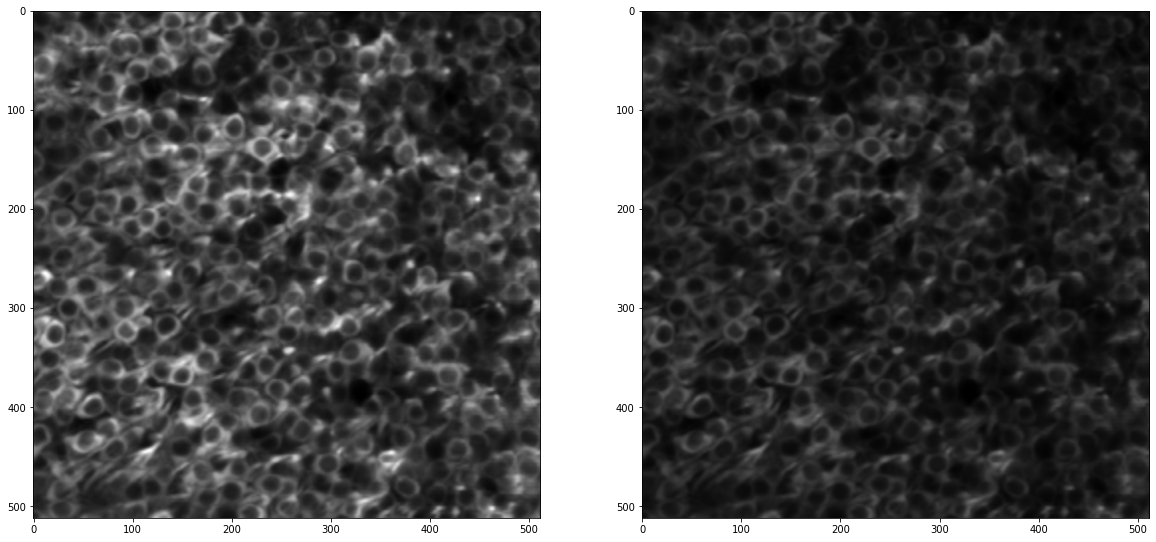

 22%|██▏       | 15/68 [00:16<00:56,  1.06s/it]

15
(512, 512)


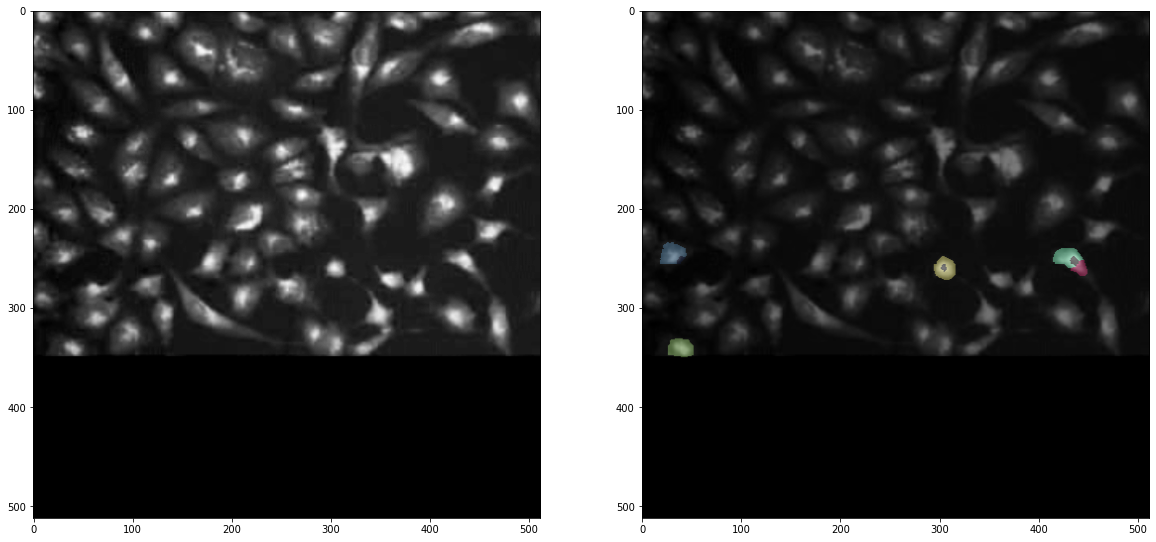

 24%|██▎       | 16/68 [00:17<00:55,  1.06s/it]

16
(512, 512)


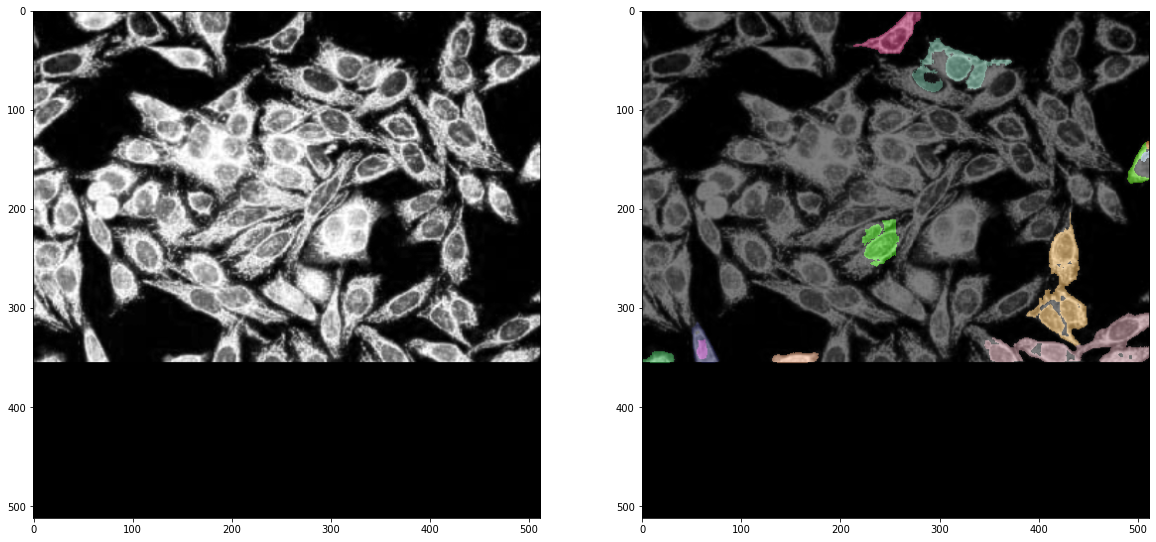

 25%|██▌       | 17/68 [00:18<00:54,  1.06s/it]

17
(512, 512)


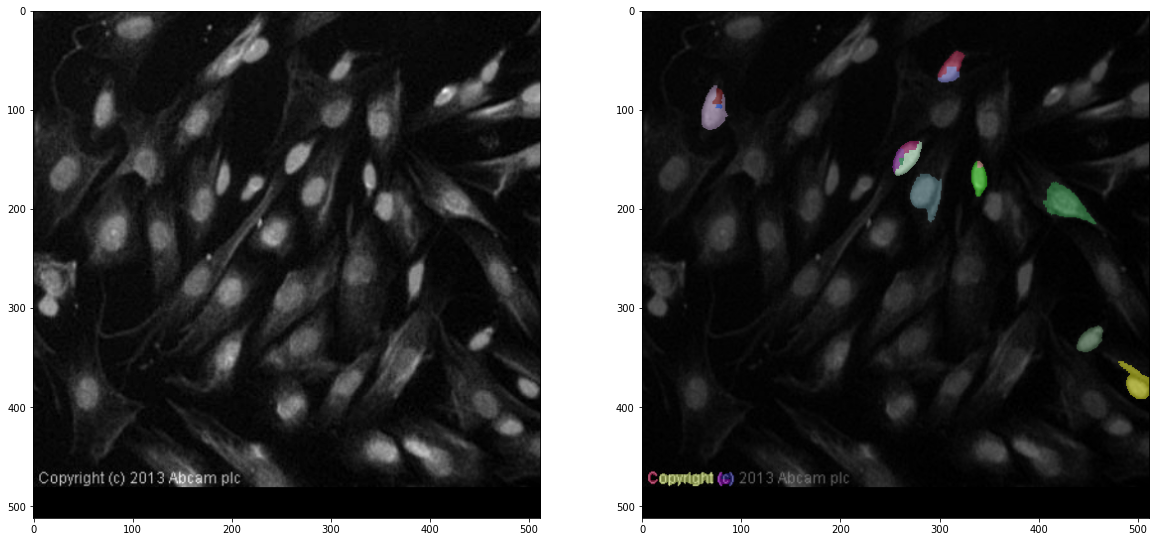

 26%|██▋       | 18/68 [00:19<00:55,  1.11s/it]

18
(512, 512)


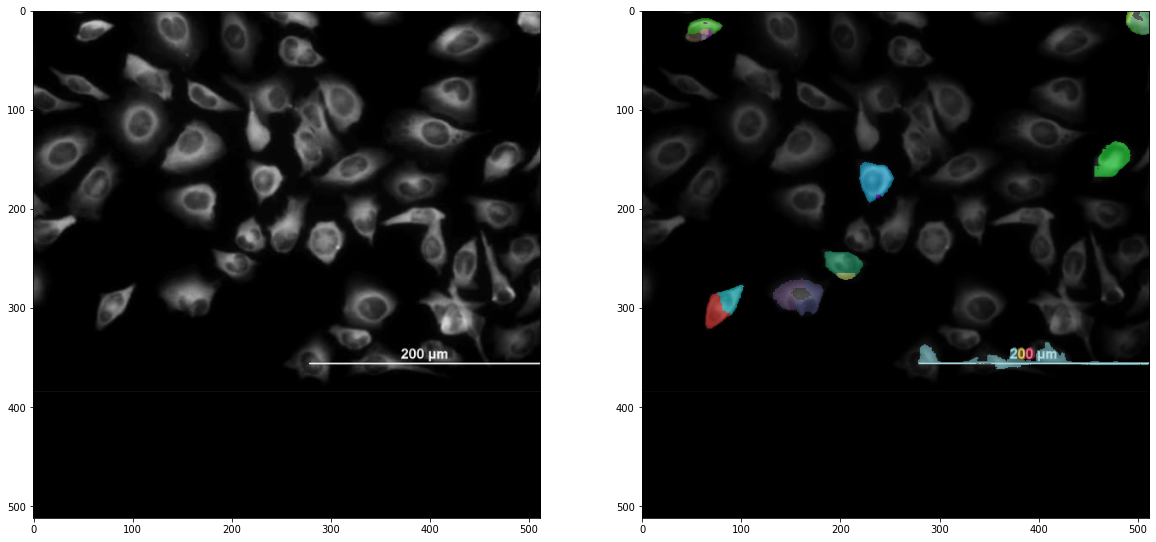

 28%|██▊       | 19/68 [00:20<00:53,  1.09s/it]

19
(512, 512)


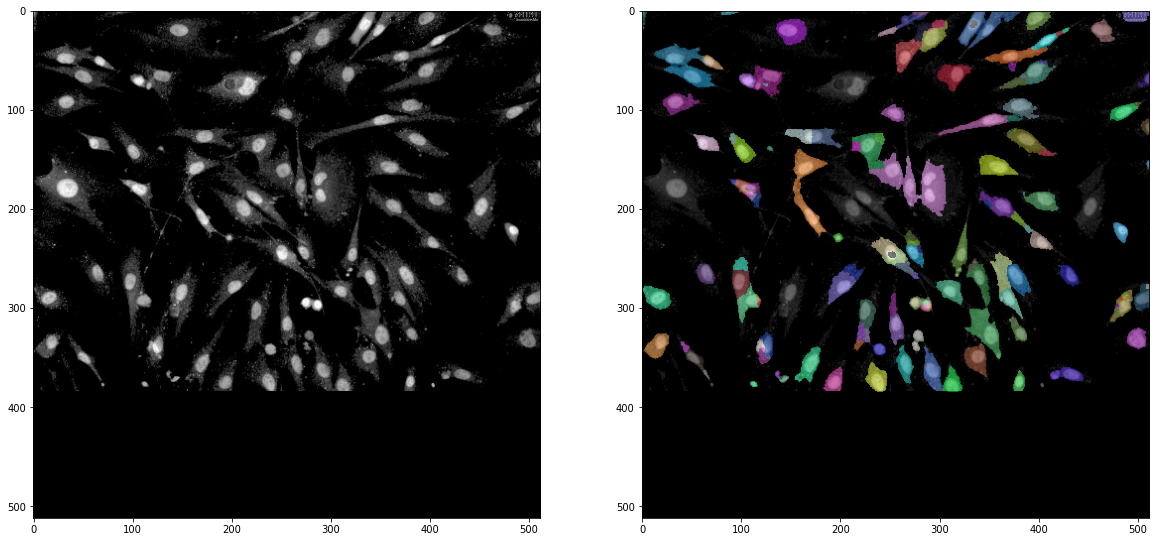

 28%|██▊       | 19/68 [00:21<00:55,  1.14s/it]


KeyboardInterrupt: 

In [ ]:
img_path = '../datasets/CellPose-test/imgs.npy'
ann_path = '../datasets/CellPose-test/anns.npy'
imgs = np.load(img_path)
anns = np.load(ann_path)[:, 0, :,:]

print(imgs.shape, anns.shape)

stats = []
print('running...')
for i in tqdm(range(len(imgs))):
    print(i)
    image_orig = imgs[i]
    ann = anns[i, :, : ].astype(np.int32)
    label, dist_map = pipeline.run(image_orig, return_dist_map=True)

    output_rgb = convert_label_to_rainbow(label)
    print(label.shape)
    # Display the output
    fig, ax = plt.subplots(1, 2, figsize=(20, 10))
    ax[0].imshow(image_orig, cmap='gray')
    ax[1].imshow(output_rgb)
    ax[1].imshow(image_orig, cmap='gray', alpha=0.5)
    plt.show()

    taus = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]

    test_stats = [matching_dataset([ann], [label], thresh=t, show_progress=False, parallel=True) for t in taus]
    stats.append([stat._asdict()['accuracy'] for stat in test_stats])

stats = np.array(stats)
print(stats.mean(axis=0))


In [ ]:
stats = stats.mean(axis=0)
#round to 4 decimal places
stats = np.round(stats, 4)
print(stats)

[0.2958 0.2565 0.2238 0.1843 0.1464 0.1052 0.0628 0.0189 0.0011]
